# EEG Data Analysis
- testing the first 5 participants'

In [1]:
## Load dependencies
import numpy as np
import pandas as pd
import mne
import yasa
import re ## regular expression operations
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## File Paths
## EDF files
eeg_dir = Path('/Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/sleep_edf')
## .csv files
hypno_dir = Path('/Users/thomasgooding/Desktop/Sleep_DXA_study/Sleep_Profiler_Data/scored_csv')

## Practice Code

In [3]:
## defining functions

def happy_birthday_song(name, age):
    print(f"Happy Birthday to you, {name}")
    print(f"You're somehow still alive at the ripe old age of {age}?!")
    print("Happy Birthday to you")
    print("That'll do Pig, that'll do")
    print(" ")

happy_birthday_song('John Paul', 36)
happy_birthday_song('Rob', 31)
happy_birthday_song('Indira', 67)

Happy Birthday to you, John Paul
You're somehow still alive at the ripe old age of 36?!
Happy Birthday to you
That'll do Pig, that'll do
 
Happy Birthday to you, Rob
You're somehow still alive at the ripe old age of 31?!
Happy Birthday to you
That'll do Pig, that'll do
 
Happy Birthday to you, Indira
You're somehow still alive at the ripe old age of 67?!
Happy Birthday to you
That'll do Pig, that'll do
 


## End Practice Code

In [4]:
## Parsing subject_id, sleep_condition, and verifying uploads worked
def parse_filename(path: Path):
    """DXA_001_normal.edf converts to ('DXA_001', 'normal'); DXA_001_9TIB.csv converts to ('DXA_001', '9TIB')"""
    subject_id, condition = path.stem.rsplit("_", 1)
    return subject_id.strip().upper(), condition.strip()

def build_manifest(eeg_dir, hypn_dir):
    eeg = pd.DataFrame(
        [(*parse_filename(p), p) for p in Path(eeg_dir).rglob("*.edf")],
        columns=["subject_id", "condition", "edf_path"])
    hyp = pd.DataFrame(
        [(*parse_filename(p), p) for p in Path(hypn_dir).rglob("*.csv")],
        columns=["subject_id", "condition", "hyp_path"])
    manifest = eeg.merge(hyp, on=["subject_id", "condition"], how="outer", indicator=True)
    return manifest.sort_values(["subject_id", "condition"]).reset_index(drop=True)

manifest = build_manifest(eeg_dir, hypno_dir)

## QC: anything missing a partner file
print(manifest["_merge"].value_counts())
print("=========")
print(manifest[manifest["_merge"] != "both"])
## Duplicate keys would silently double-count nights
assert not manifest.duplicated(["subject_id", "condition"]).any(), "Duplicate subject/condition"

manifest = manifest[manifest["_merge"] == "both"].drop(columns="_merge")

_merge
both          20
left_only      0
right_only     0
Name: count, dtype: int64
Empty DataFrame
Columns: [subject_id, condition, edf_path, hyp_path, _merge]
Index: []


In [5]:
manifest
## view uploaded pairs of EEG.edf and hypnogram.csv files

,subject_id,condition,edf_path,hyp_path
0,DXA_001,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
1,DXA_001,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
2,DXA_002,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
3,DXA_002,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
4,DXA_003,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
5,DXA_003,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
6,DXA_004,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
7,DXA_004,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
8,DXA_005,9TIB,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...
9,DXA_005,normal,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...,/Users/thomasgooding/Desktop/Sleep_DXA_study/S...


# Formatting Hypnograms

In [6]:
hyp_raw = pd.read_csv(manifest.iloc[0]["hyp_path"])
print(manifest.iloc[0][["subject_id", "condition"]].to_dict())
print(hyp_raw.head(10))
print(hyp_raw.dtypes)
print(len(hyp_raw), "rows ->", round(len(hyp_raw) * 30 / 3600, 2), "hours at 30 s epochs")

{'subject_id': 'DXA_001', 'condition': '9TIB'}
   Subject #  Epoch #  Night    StudyDate ElapsedTime  ElapsedTime(sec)  \
0  421000020        1      1  07 Oct 2019    00:00:15                15   
1  421000020        2      1  07 Oct 2019    00:00:45                45   
2  421000020        3      1  07 Oct 2019    00:01:15                75   
3  421000020        4      1  07 Oct 2019    00:01:45               105   
4  421000020        5      1  07 Oct 2019    00:02:15               135   
5  421000020        6      1  07 Oct 2019    00:02:45               165   
6  421000020        7      1  07 Oct 2019    00:03:15               195   
7  421000020        8      1  07 Oct 2019    00:03:45               225   
8  421000020        9      1  07 Oct 2019    00:04:15               255   
9  421000020       10      1  07 Oct 2019    00:04:45               285   

  ClockTime  PrimaryAutoStage  SecondaryAutoStage  TechEditStage  Stage final  \
0  23:08:18                 0                 

#### Sleep Profiler Scoring Key

Primary stage classification from auto-scoring:
- 0 = wake
- 1 = N1
- 2 = N2
- 3 = N3
- 4 = L2 (light N2)
- 5 = REM
- 6 = NOS (sleep not otherwise specified)
- 9 = INVALID
- 14 = NRH (Non-REM hypertonia)
- 33 = Atypical N3
- 55 = RSWA (REM sleep without atonia)

In [7]:
# ## label the epoch column and final stage scored sleep columns
# EPOCH_COL = "epoch_#"
# STAGE_COL = "stage_final"

# STAGE_MAP = {
#     0: "WAKE",
#     1: "N1",
#     2: "N2",
#     3: "N3",
#     4: "N2",    # L2 (light N2)
#     5: "REM",
#     6: "UNS",   # Sleep not otherwise specified
#     9: "UNS",   # INVALID
#     14: "N2",   # NRH
#     33: "N3",   # atypical N3
#     55: "REM",  # REM sleep without atonia
# }

# # RAW_LABELS = {0: "wake", 1: "n1", 2: "n2", 3: "n3", 4: "l2", 5: "rem",
# #               6: "nos", 9: "invalid", 14: "nrh", 33: "atyp_n3", 55: "rswa"}

# def load_hypno(csv_path):
#     df = pd.read_csv(csv_path, encoding="utf-8-sig")
#     df.columns = (df.columns.str.strip()
#                             .str.lower()
#                             .str.replace(r"\s+", "_", regex=True))

#     missing = [c for c in (EPOCH_COL, STAGE_COL) if c not in df.columns]
#     if missing:
#         raise KeyError(f"{missing} not found. Columns present: {df.columns.tolist()}")

#     df = df.sort_values(EPOCH_COL).reset_index(drop=True)

#     if not (np.diff(df[EPOCH_COL].to_numpy()) == 1).all():
#         raise ValueError("epoch_# is not contiguous (gaps or duplicates)")

#     stages = df[STAGE_COL].map(STAGE_MAP)
#     if stages.isna().any():
#         bad = sorted(df.loc[stages.isna(), STAGE_COL].unique())
#         raise ValueError(f"Unmapped stage codes: {bad}")

#     hyp = yasa.Hypnogram(stages.to_numpy(), freq="30s")
#     return hyp, df[STAGE_COL]

In [ ]:
## label the epoch column and final stage scored sleep columns
EPOCH_COL = "epoch_#"
STAGE_COL = "stage_final"
SECONDARY_COL = "secondaryautostage"

STAGE_MAP = {
    0 : 'WAKE',
    1: 'N1',
    2: 'N2',
    3: 'N3',
    4: 'N2', ## Light N2 (Still N2)
    5: 'REM', 
    6: 'UNS', ## sleep not otherwise specified
    9: 'UNS', ## artifact/ INVALID
    14: 'N2', ## Non-REM hypertonia  --> map to secondary autoscored criteria vs NRH
    33: 'N3', ## atypical N3, mapped to N3
    55: 'REM' ## REM without atonia, mapped to REM
}

# RAW_LABELS = {0: "wake", 1: "n1", 2: "n2", 3: "n3", 4: "l2", 5: "rem",
#               6: "nos", 9: "invalid", 14: "nrh", 33: "atyp_n3", 55: "rswa"}
def load_hypno(csv_path):
    df = pd.read_csv(csv_path, encoding="utf-8-sig")
    df.columns = (df.columns.str.strip()
                            .str.lower()
                            .str.replace(r"\s+", "_", regex=True))

    missing = [c for c in (EPOCH_COL, STAGE_COL, SECONDARY_COL) if c not in df.columns]
    if missing:
        raise KeyError(f"{missing} not found. Columns present: {df.columns.tolist()}")

    df = df.sort_values(EPOCH_COL).reset_index(drop=True)

    if not (np.diff(df[EPOCH_COL].to_numpy()) == 1).all():
        raise ValueError("epoch_# is not contiguous (gaps or duplicates)")

    ## When the final stage is NRH, take the secondary auto stage instead (e.g., N2, N3).
    ## A missing secondary value leaves the epoch as NRH, which falls back to N2.
    alt_stage = df[STAGE_COL].where(df[STAGE_COL] != 14, df[SECONDARY_COL])

    stages = alt_stage.map(STAGE_MAP)
    if stages.isna().any():
        bad = sorted(alt_stage[stages.isna()].unique())
        raise ValueError(f"Unmapped stage codes: {bad}")

    hyp = yasa.Hypnogram(stages.to_numpy(), freq="30s")
    return hyp, alt_stage

In [9]:
## visually inspect first row hypnogram
## DXA_001 9TIB condition == 9.12 hours worth of hypnogram sleep data
hyp, raw_codes = load_hypno(manifest.iloc[0]["hyp_path"])
print(manifest.iloc[0][["subject_id", "condition"]].to_dict())
print(len(hyp), "epochs ->", round(len(hyp) * 0.5 / 60, 2), "hours")

hyp.sleep_statistics()        # dict of stats, durations in minutes
# hyp.plot_hypnogram()         # quick visual check of the staging

{'subject_id': 'DXA_001', 'condition': '9TIB'}
1095 epochs -> 9.12 hours


{'TIB': np.float64(547.5),
 'SPT': np.float64(544.0),
 'WASO': np.float64(14.5),
 'TST': np.float64(529.5),
 'SE': np.float64(96.7123),
 'SME': np.float64(97.3346),
 'SFI': np.float64(1.0765),
 'SOL': np.float64(3.0),
 'SOL_5min': np.float64(8.0),
 'Lat_REM': np.float64(59.5),
 'WAKE': np.float64(18.0),
 'N1': np.float64(32.5),
 'N2': np.float64(228.0),
 'N3': np.float64(127.0),
 'REM': np.float64(142.0),
 '%N1': np.float64(6.1379),
 '%N2': np.float64(43.0595),
 '%N3': np.float64(23.9849),
 '%REM': np.float64(26.8178)}

In [10]:
hyp.sleep_statistics() 

{'TIB': np.float64(547.5),
 'SPT': np.float64(544.0),
 'WASO': np.float64(14.5),
 'TST': np.float64(529.5),
 'SE': np.float64(96.7123),
 'SME': np.float64(97.3346),
 'SFI': np.float64(1.0765),
 'SOL': np.float64(3.0),
 'SOL_5min': np.float64(8.0),
 'Lat_REM': np.float64(59.5),
 'WAKE': np.float64(18.0),
 'N1': np.float64(32.5),
 'N2': np.float64(228.0),
 'N3': np.float64(127.0),
 'REM': np.float64(142.0),
 '%N1': np.float64(6.1379),
 '%N2': np.float64(43.0595),
 '%N3': np.float64(23.9849),
 '%REM': np.float64(26.8178)}

{'subject_id': 'DXA_001', 'condition': 'normal'}
1118 epochs -> 9.32 hours


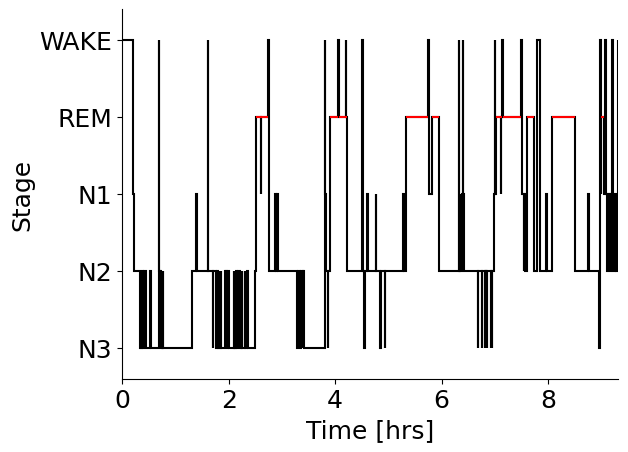

In [11]:
## visually inspect second row hypnogram data
## DXA_001 'normal' sleep condition, 9.32 hours of hypnogram data recorded
hyp, raw_codes = load_hypno(manifest.iloc[1]["hyp_path"])
print(manifest.iloc[1][["subject_id", "condition"]].to_dict())
print(len(hyp), "epochs ->", round(len(hyp) * 0.5 / 60, 2), "hours")

hyp.sleep_statistics()        # dict of stats, durations in minutes
hyp.plot_hypnogram();         # quick visual check of the staging

# Sleep Statistics

In [12]:
rows = []
for r in manifest.itertuples():
    df = pd.read_csv(r.hyp_path, encoding="utf-8-sig")
    df.columns = df.columns.str.strip()
    rows.append({
        "subject_id": r.subject_id,
        "condition": r.condition,
        "file": Path(r.hyp_path).name,
        "n_rows": len(df),
        "hours": round(len(df) * 0.5 / 60, 2),
        "study_date": df["StudyDate"].iloc[0],
        "night": df["Night"].iloc[0],
        "start_clock": df["ClockTime"].iloc[0],
        "end_clock": df["ClockTime"].iloc[-1],
    })

length_check = pd.DataFrame(rows)
display(length_check)
print(length_check.groupby("condition")["n_rows"].describe())

,subject_id,condition,file,n_rows,hours,study_date,night,start_clock,end_clock
0,DXA_001,9TIB,DXA_001_9TIB.csv,1095,9.12,07 Oct 2019,1,23:08:18,08:15:18
1,DXA_001,normal,DXA_001_normal.csv,1118,9.32,26 Sep 2019,1,22:41:54,08:00:24
2,DXA_002,9TIB,DXA_002_9TIB.csv,1088,9.07,29 Sep 2019,1,01:56:49,11:00:19
3,DXA_002,normal,DXA_002_normal.csv,865,7.21,26 Sep 2019,1,02:17:07,09:29:07
4,DXA_003,9TIB,DXA_003_9TIB.csv,812,6.77,05 Oct 2019,1,01:21:28,08:06:58
5,DXA_003,normal,DXA_003_normal.csv,599,4.99,28 Sep 2019,1,02:11:59,07:10:59
6,DXA_004,9TIB,DXA_004_9TIB.csv,1119,9.32,09 Oct 2019,1,23:30:46,08:49:46
7,DXA_004,normal,DXA_004_normal.csv,697,5.81,04 Oct 2019,1,01:11:58,06:59:58
8,DXA_005,9TIB,DXA_005_9TIB.csv,1083,9.03,09 Oct 2019,1,23:29:57,08:30:57
9,DXA_005,normal,DXA_005_normal.csv,928,7.73,03 Oct 2019,1,00:43:44,08:28:01


           count    mean         std    min      25%     50%      75%     max
condition                                                                    
9TIB        10.0  1059.4   88.115076  812.0  1074.75  1083.0  1093.25  1119.0
normal      10.0   821.4  153.179778  599.0   717.00   820.0   912.25  1118.0


In [13]:
rows, failed = [], []
for r in manifest.itertuples():
    try:
        hyp, raw_codes = load_hypno(r.hyp_path)
        stats = hyp.sleep_statistics()

        counts = raw_codes.map(STAGE_MAP).value_counts()
        raw_counts = {f"n_{lab}_epochs": int(counts.get(lab, 0)) for lab in STAGE_MAP.values()}

        rows.append({"subject_id": r.subject_id, "condition": r.condition,
                     "n_epochs": len(hyp), **stats, **raw_counts})
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

sleep_statistics_df = pd.DataFrame(rows)
sleep_statistics_df["condition"] = pd.Categorical(
sleep_statistics_df["condition"], categories=["normal", "9TIB"])
sleep_statistics_df = (sleep_statistics_df.sort_values(["subject_id", "condition"]).reset_index(drop=True))

print(f"{len(sleep_statistics_df)} nights processed, {len(failed)} failed")
for f in failed:
    print(f)

20 nights processed, 0 failed


In [14]:
sleep_statistics_df.head(20)

,subject_id,condition,n_epochs,TIB,SPT,WASO,TST,SE,SME,SFI,...,%N2,%N3,%REM,n_WAKE_epochs,n_N1_epochs,n_N2_epochs,n_N3_epochs,n_REM_epochs,n_UNS_epochs,UNS
0,DXA_001,normal,1118,559.0,546.5,13.0,533.5,95.4383,97.6212,1.0122,...,48.9222,21.9306,24.1799,51,53,522,234,258,0,NaN
1,DXA_001,9TIB,1095,547.5,544.0,14.5,529.5,96.7123,97.3346,1.0765,...,43.0595,23.9849,26.8178,36,65,456,254,284,0,NaN
2,DXA_002,normal,865,432.5,400.5,27.0,371.5,85.8960,92.7591,2.7456,...,29.7443,45.2221,16.1507,78,66,221,336,120,44,22.0
3,DXA_002,9TIB,1088,544.0,473.0,35.5,435.0,79.9632,91.9662,2.4138,...,20.6897,50.6897,24.5977,99,35,180,441,214,119,59.5
4,DXA_003,normal,599,299.5,296.0,12.5,283.5,94.6578,95.7770,1.5873,...,32.9806,36.3316,23.8095,29,39,187,206,135,3,1.5
5,DXA_003,9TIB,812,406.0,400.0,13.0,387.0,95.3202,96.7500,1.7829,...,33.7209,48.7080,0.9044,38,129,261,377,7,0,NaN
6,DXA_004,normal,697,348.5,338.0,7.0,330.5,94.8350,97.7811,0.9077,...,38.4266,27.0802,28.8956,35,37,254,179,191,1,0.5
7,DXA_004,9TIB,1119,559.5,555.5,46.5,509.0,90.9741,91.6292,2.0629,...,39.0963,17.9764,37.0334,101,60,398,183,377,0,NaN
8,DXA_005,normal,928,464.0,462.0,26.5,425.5,91.7026,92.0996,2.2562,...,28.0846,47.0035,7.7556,57,146,239,400,66,20,10.0
9,DXA_005,9TIB,1083,541.5,515.5,34.0,480.0,88.6427,93.1135,1.6875,...,33.5417,32.7083,26.3542,120,71,322,314,253,3,1.5


In [15]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)
sleep_statistics_df.head()

,subject_id,condition,n_epochs,TIB,SPT,WASO,TST,SE,SME,SFI,SOL,SOL_5min,Lat_REM,WAKE,N1,N2,N3,REM,%N1,%N2,%N3,%REM,n_WAKE_epochs,n_N1_epochs,n_N2_epochs,n_N3_epochs,n_REM_epochs,n_UNS_epochs,UNS
0,DXA_001,normal,1118,559.0,546.5,13.0,533.5,95.4383,97.6212,1.0122,12.0,12.0,150.5,25.5,26.5,261.0,117.0,129.0,4.9672,48.9222,21.9306,24.1799,51,53,522,234,258,0,NaN
1,DXA_001,9TIB,1095,547.5,544.0,14.5,529.5,96.7123,97.3346,1.0765,3.0,8.0,59.5,18.0,32.5,228.0,127.0,142.0,6.1379,43.0595,23.9849,26.8178,36,65,456,254,284,0,NaN
2,DXA_002,normal,865,432.5,400.5,27.0,371.5,85.8960,92.7591,2.7456,22.0,22.0,119.5,39.0,33.0,110.5,168.0,60.0,8.8829,29.7443,45.2221,16.1507,78,66,221,336,120,44,22.0
3,DXA_002,9TIB,1088,544.0,473.0,35.5,435.0,79.9632,91.9662,2.4138,11.5,11.5,115.5,49.5,17.5,90.0,220.5,107.0,4.0230,20.6897,50.6897,24.5977,99,35,180,441,214,119,59.5
4,DXA_003,normal,599,299.5,296.0,12.5,283.5,94.6578,95.7770,1.5873,2.0,2.0,50.0,14.5,19.5,93.5,103.0,67.5,6.8783,32.9806,36.3316,23.8095,29,39,187,206,135,3,1.5


In [16]:
# sleep_statistics_df.groupby('condition', as_index=True, observed=True)[['TIB', 'SPT','TST', 'WASO', 'SE','SOL','Lat_REM','SME', 'SFI']].describe().round(2).T

# display(sleep_descriptives_df)

# Sleep Spindles

In [ ]:
EEG_CH = "EEG4"
INCLUDE = (2, 3)                                  # YASA int codes: 2 = N2, 3 = N3
STAGE_NAMES = {1: "N1", 2: "N2", 3: "N3", 4: "REM"}
EPOCH_SEC = 30

## Load EEG file (raw)
def load_eeg(edf_path, ch=EEG_CH):
    raw = mne.io.read_raw_edf(edf_path, preload=True, verbose="ERROR")
    if ch not in raw.ch_names:
        raise KeyError(f"{ch} not in EDF channels: {raw.ch_names}")
    raw.pick([ch])
    return raw

## Load hypnogram
def hypno_to_samples(hyp, n_samples, sf):
    """Stretch the 30 s hypnogram to one value per EEG sample (YASA int codes)."""
    h = hyp.as_int().to_numpy()
    up = np.repeat(h, int(round(EPOCH_SEC * sf)))
    if len(up) >= n_samples:
        return up[:n_samples]
    return np.pad(up, (0, n_samples - len(up)), constant_values=-2)   # pad with 'unscored'

## add participant identifying information to df
def tag(df, subject_id, condition):
    df = df.reset_index(drop=True).copy()
    df.insert(0, "condition", condition)
    df.insert(0, "subject_id", subject_id)
    return df

## detect sleep spindle function
def detect_spindles_night(edf_path, hyp, subject_id, condition):
    raw = load_eeg(edf_path)
    sf = raw.info["sfreq"]
    data = raw.get_data(units="uV")                       # shape (1, n_samples), in microvolts
    hyp_up = hypno_to_samples(hyp, data.shape[1], sf)

    sp = yasa.spindles_detect(data, sf, ch_names=[EEG_CH], hypno=hyp_up,
                              freq_sp =(12,15), ## YASA Default; AASM defines spindles from 11-16 Hz
                              duration=(0.5,2),
                              min_distance=500,
                              include=INCLUDE, verbose=False)

    if sp is None:                                        # YASA returns None if nothing detected
        events, by_stage = pd.DataFrame(), pd.DataFrame()
    else:
        events = sp.summary()
        by_stage = sp.summary(grp_chan=True, grp_stage=True).reset_index()
        for df in (events, by_stage):
            df["Stage"] = df["Stage"].map(STAGE_NAMES)

    meta = {"subject_id": subject_id, "condition": condition, "sf": sf,
            "edf_start": raw.info["meas_date"],
            "edf_min": round(data.shape[1] / sf / 60, 2),
            "hypno_min": round(len(hyp) * EPOCH_SEC / 60, 2),
            "n_spindles": len(events)}
    return tag(events, subject_id, condition), tag(by_stage, subject_id, condition), meta

In [36]:
events_list, stage_list, meta_list, failed = [], [], [], []

for r in manifest.itertuples():
    try:
        hyp, _ = load_hypno(r.hyp_path)
        events, by_stage, meta = detect_spindles_night(r.edf_path, hyp, r.subject_id, r.condition)
        events_list.append(events); stage_list.append(by_stage); meta_list.append(meta)
    except Exception as e:
        failed.append((r.subject_id, r.condition, repr(e)))

print(f"{len(meta_list)} nights processed, {len(failed)} failed")
for f in failed[:10]:
    print(f)

if meta_list:
    spindle_events_df   = pd.concat(events_list, ignore_index=True)   ## one row per spindle
    spindle_by_stage_df = pd.concat(stage_list, ignore_index=True)    ## group spindles by stage
    spindle_meta_df     = pd.DataFrame(meta_list)

    for df in (spindle_events_df, spindle_by_stage_df, spindle_meta_df):
        df["condition"] = pd.Categorical(df["condition"], categories=["normal", "9TIB"])

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.1s finished
[Parallel(n_jobs=1)]

20 nights processed, 0 failed


## Spindle meta data df

In [19]:
## EDF length vs hypnogram length, spindle counts per night
spindle_meta_df

,subject_id,condition,sf,edf_start,edf_min,hypno_min,n_spindles
0,DXA_001,9TIB,256.0,2000-01-01 00:00:00+00:00,548.48,547.5,873
1,DXA_001,normal,256.0,2000-01-01 00:00:00+00:00,559.55,559.0,1086
2,DXA_002,9TIB,256.0,2000-01-01 00:00:00+00:00,544.58,544.0,44
3,DXA_002,normal,256.0,2000-01-01 00:00:00+00:00,433.28,432.5,89
4,DXA_003,9TIB,256.0,2000-01-01 00:00:00+00:00,407.10,406.0,72
5,DXA_003,normal,256.0,2000-01-01 00:00:00+00:00,300.38,299.5,141
6,DXA_004,9TIB,256.0,2000-01-01 00:00:00+00:00,560.87,559.5,370
7,DXA_004,normal,256.0,2000-01-01 00:00:00+00:00,349.40,348.5,156
8,DXA_005,9TIB,256.0,2000-01-01 00:00:00+00:00,542.27,541.5,250
9,DXA_005,normal,256.0,2000-01-01 00:00:00+00:00,465.37,464.0,102


<Axes: xlabel='edf_min', ylabel='n_spindles'>

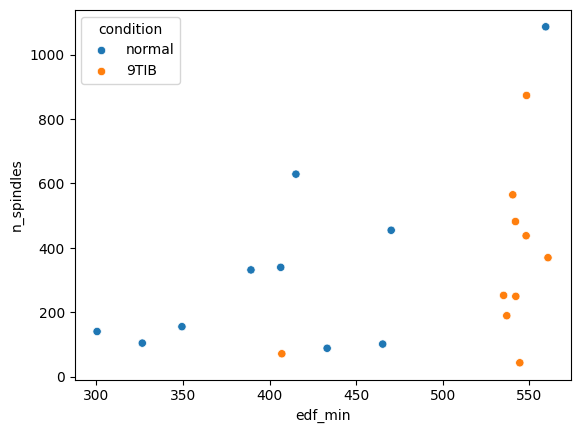

In [20]:
sns.scatterplot(data=spindle_meta_df, x='edf_min', y='n_spindles', hue='condition')

## Spindle events df (not grouped by stage)

In [21]:
spindle_events_df.head()

,subject_id,condition,Start,Peak,End,Duration,Amplitude,AmpFiltered,RMS,AbsPower,RelPower,Frequency,Oscillations,Symmetry,Stage,Channel,IdxChannel
0,DXA_001,9TIB,940.972656,941.296875,941.656250,0.683594,26.469990,23.556170,6.724582,1.732186,0.404558,13.023735,8.0,0.471591,N2,EEG4,0
1,DXA_001,9TIB,972.945312,973.753906,973.851562,0.906250,44.486865,24.842268,7.929595,1.643523,0.377046,13.001943,12.0,0.888412,N2,EEG4,0
2,DXA_001,9TIB,977.562500,978.121094,978.703125,1.140625,51.215745,38.503927,10.585567,2.172309,0.703755,12.635204,15.0,0.488055,N2,EEG4,0
3,DXA_001,9TIB,993.945312,994.324219,994.718750,0.773438,40.321819,29.682983,8.460560,1.873994,0.559406,12.780044,10.0,0.487437,N2,EEG4,0
4,DXA_001,9TIB,1016.617188,1017.363281,1017.558594,0.941406,30.087682,16.420342,6.399633,1.749540,0.508052,12.713356,11.0,0.789256,N2,EEG4,0


In [22]:
spindle_events_df.shape

(6972, 17)

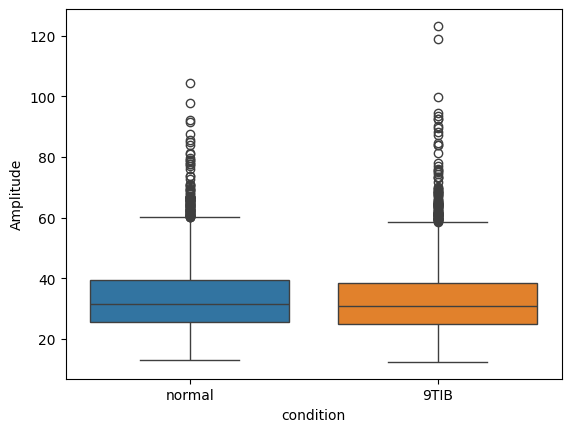

In [23]:
sns.boxplot(data=spindle_events_df, x='condition', y='Amplitude', hue='condition')

plt.show()

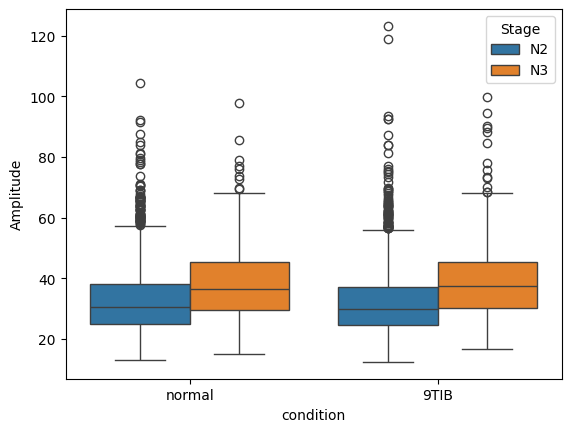

In [24]:
sns.boxplot(data=spindle_events_df, x='condition', y='Amplitude', hue='Stage')

plt.show()

## Grouped Spindle DF

In [25]:
spindle_by_stage_df.round(2).head()

,subject_id,condition,Stage,Channel,Count,Density,Duration,Amplitude,AmpFiltered,RMS,AbsPower,RelPower,Frequency,Oscillations,Symmetry
0,DXA_001,9TIB,N2,EEG4,817,3.58,0.82,31.28,19.00,6.73,1.60,0.39,12.68,10.01,0.51
1,DXA_001,9TIB,N3,EEG4,56,0.44,0.71,34.67,20.56,7.58,1.74,0.36,12.60,8.61,0.50
2,DXA_001,normal,N2,EEG4,990,3.79,0.81,32.06,19.97,6.92,1.64,0.41,12.77,10.04,0.52
3,DXA_001,normal,N3,EEG4,96,0.82,0.75,36.48,21.75,8.07,1.77,0.35,12.60,9.07,0.52
4,DXA_002,9TIB,N2,EEG4,31,0.34,0.73,39.01,23.35,8.84,1.87,0.33,12.33,8.87,0.52


In [26]:
spindle_events_df.groupby(["subject_id", "condition", "Stage"], observed=True).size()

subject_id  condition  Stage
DXA_001     normal     N2       990
                       N3        96
            9TIB       N2       817
                       N3        56
DXA_002     normal     N2        71
                       N3        18
            9TIB       N2        31
                       N3        13
DXA_003     normal     N2       127
                       N3        14
            9TIB       N2        59
                       N3        13
DXA_004     normal     N2       148
                       N3         8
            9TIB       N2       360
                       N3        10
DXA_005     normal     N2        72
                       N3        30
            9TIB       N2       179
                       N3        71
DXA_008     normal     N2       266
                       N3        74
            9TIB       N2       509
                       N3        56
DXA_010     normal     N2       309
                       N3        23
            9TIB       N2       243

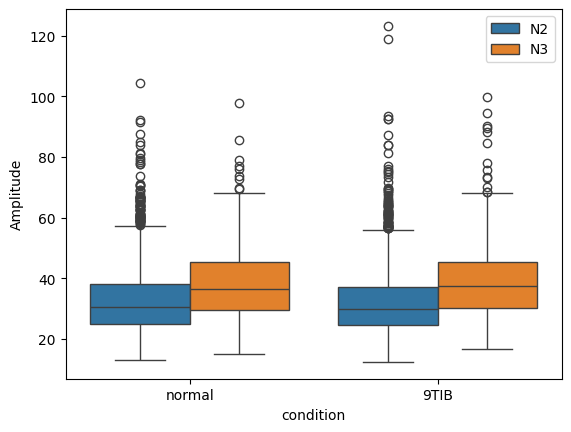

In [27]:
sns.boxplot(data= spindle_events_df, x='condition', y='Amplitude', hue='Stage')

plt.legend(bbox_to_anchor=(1,1))
plt.show()

In [28]:
spindle_events_df_grouped = spindle_by_stage_df.groupby('subject_id', as_index=False)

spindle_events_df_grouped

## merging sleep statistics with sleep spindle data

In [29]:
sleep_statistics_df.head()

,subject_id,condition,n_epochs,TIB,SPT,WASO,TST,SE,SME,SFI,SOL,SOL_5min,Lat_REM,WAKE,N1,N2,N3,REM,%N1,%N2,%N3,%REM,n_WAKE_epochs,n_N1_epochs,n_N2_epochs,n_N3_epochs,n_REM_epochs,n_UNS_epochs,UNS
0,DXA_001,normal,1118,559.0,546.5,13.0,533.5,95.4383,97.6212,1.0122,12.0,12.0,150.5,25.5,26.5,261.0,117.0,129.0,4.9672,48.9222,21.9306,24.1799,51,53,522,234,258,0,NaN
1,DXA_001,9TIB,1095,547.5,544.0,14.5,529.5,96.7123,97.3346,1.0765,3.0,8.0,59.5,18.0,32.5,228.0,127.0,142.0,6.1379,43.0595,23.9849,26.8178,36,65,456,254,284,0,NaN
2,DXA_002,normal,865,432.5,400.5,27.0,371.5,85.8960,92.7591,2.7456,22.0,22.0,119.5,39.0,33.0,110.5,168.0,60.0,8.8829,29.7443,45.2221,16.1507,78,66,221,336,120,44,22.0
3,DXA_002,9TIB,1088,544.0,473.0,35.5,435.0,79.9632,91.9662,2.4138,11.5,11.5,115.5,49.5,17.5,90.0,220.5,107.0,4.0230,20.6897,50.6897,24.5977,99,35,180,441,214,119,59.5
4,DXA_003,normal,599,299.5,296.0,12.5,283.5,94.6578,95.7770,1.5873,2.0,2.0,50.0,14.5,19.5,93.5,103.0,67.5,6.8783,32.9806,36.3316,23.8095,29,39,187,206,135,3,1.5


In [30]:
sleep_spindles_stats_df = pd.merge(sleep_statistics_df,spindle_by_stage_df, on = ['subject_id', 'condition']
)

sleep_spindles_stats_df.head()

,subject_id,condition,n_epochs,TIB,SPT,WASO,TST,SE,SME,SFI,SOL,SOL_5min,Lat_REM,WAKE,N1,N2,N3,REM,%N1,%N2,%N3,%REM,n_WAKE_epochs,n_N1_epochs,n_N2_epochs,n_N3_epochs,n_REM_epochs,n_UNS_epochs,UNS,Stage,Channel,Count,Density,Duration,Amplitude,AmpFiltered,RMS,AbsPower,RelPower,Frequency,Oscillations,Symmetry
0,DXA_001,normal,1118,559.0,546.5,13.0,533.5,95.4383,97.6212,1.0122,12.0,12.0,150.5,25.5,26.5,261.0,117.0,129.0,4.9672,48.9222,21.9306,24.1799,51,53,522,234,258,0,NaN,N2,EEG4,990,3.793103,0.813632,32.060095,19.974734,6.916408,1.638518,0.414650,12.770555,10.035354,0.518251
1,DXA_001,normal,1118,559.0,546.5,13.0,533.5,95.4383,97.6212,1.0122,12.0,12.0,150.5,25.5,26.5,261.0,117.0,129.0,4.9672,48.9222,21.9306,24.1799,51,53,522,234,258,0,NaN,N3,EEG4,96,0.820513,0.749390,36.480941,21.751118,8.070365,1.771553,0.352413,12.602994,9.072917,0.522457
2,DXA_001,9TIB,1095,547.5,544.0,14.5,529.5,96.7123,97.3346,1.0765,3.0,8.0,59.5,18.0,32.5,228.0,127.0,142.0,6.1379,43.0595,23.9849,26.8178,36,65,456,254,284,0,NaN,N2,EEG4,817,3.583333,0.822823,31.280775,19.002392,6.728987,1.603174,0.394165,12.681452,10.008568,0.514799
3,DXA_001,9TIB,1095,547.5,544.0,14.5,529.5,96.7123,97.3346,1.0765,3.0,8.0,59.5,18.0,32.5,228.0,127.0,142.0,6.1379,43.0595,23.9849,26.8178,36,65,456,254,284,0,NaN,N3,EEG4,56,0.440945,0.707520,34.667545,20.559063,7.584764,1.737254,0.356738,12.598059,8.607143,0.501274
4,DXA_002,normal,865,432.5,400.5,27.0,371.5,85.8960,92.7591,2.7456,22.0,22.0,119.5,39.0,33.0,110.5,168.0,60.0,8.8829,29.7443,45.2221,16.1507,78,66,221,336,120,44,22.0,N2,EEG4,71,0.642534,0.781910,37.297620,22.087430,8.272572,1.739966,0.318348,12.346468,9.295775,0.530710


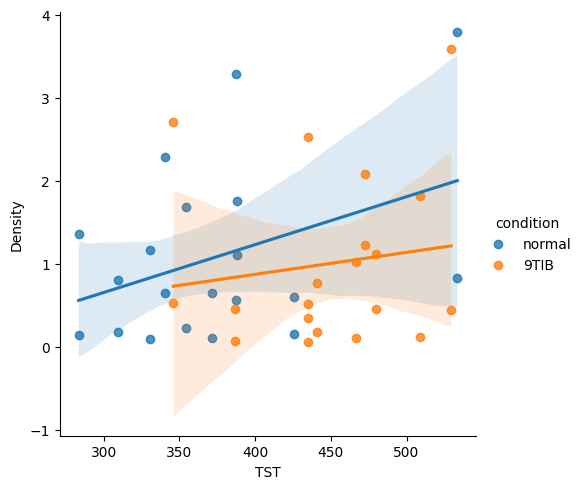

In [31]:
sns.lmplot(data = sleep_spindles_stats_df, x='TST', y='Density', hue='condition')

plt.show()

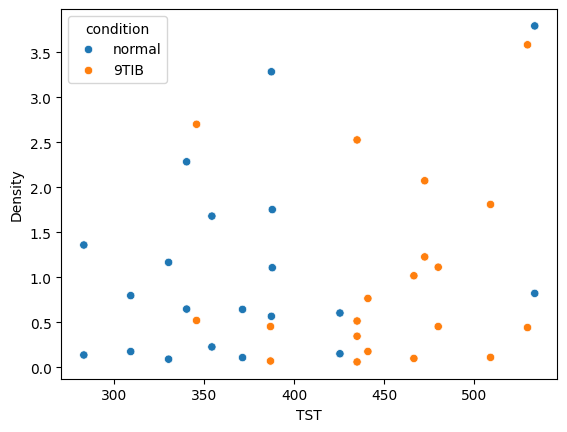

In [34]:
sns.scatterplot(data = sleep_spindles_stats_df, x='TST', y='Density', hue='condition')

plt.show()

# Stop

In [32]:
stop 
## stop

NameError: name 'stop' is not defined